## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")



00: Importing torch...done; this took 0.0031ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.3s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_sqrtVar_vol_simple 1.1 [2d2edb96|acaee5f1ce9f88de] created.
00: Trainer for 'AEC train_sqrtVar_vol_simple 1.1 [2d2edb96|acaee5f1ce9f88de]' on data acaee5f1ce9f88de
00: ===================================================================================================
01:   Restoring checkpoint from '/media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_vol_simple 75c1566e/last.pt'... done; this took 0.068s.
01:   Model is ready. Current epoch to train is 48.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_vol_simple 75c1566e/.
00: Launching 'AEC train_sqrtVar_vol_simple 1.1 [2d2edb96|acaee5f1ce9f88de]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 10 batches per epoch, and a batch size of 2048 for valuation. The model has 43233 parameters. Resuming from epoch 48.
00: Training 'train_sqrtVa

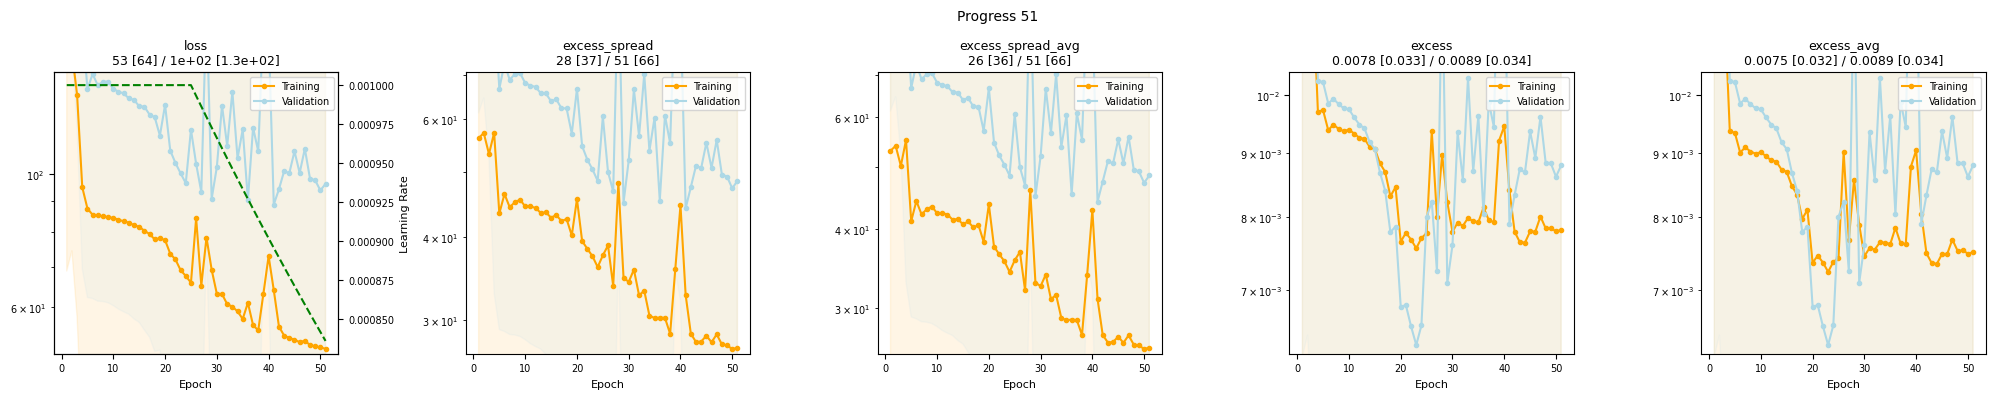

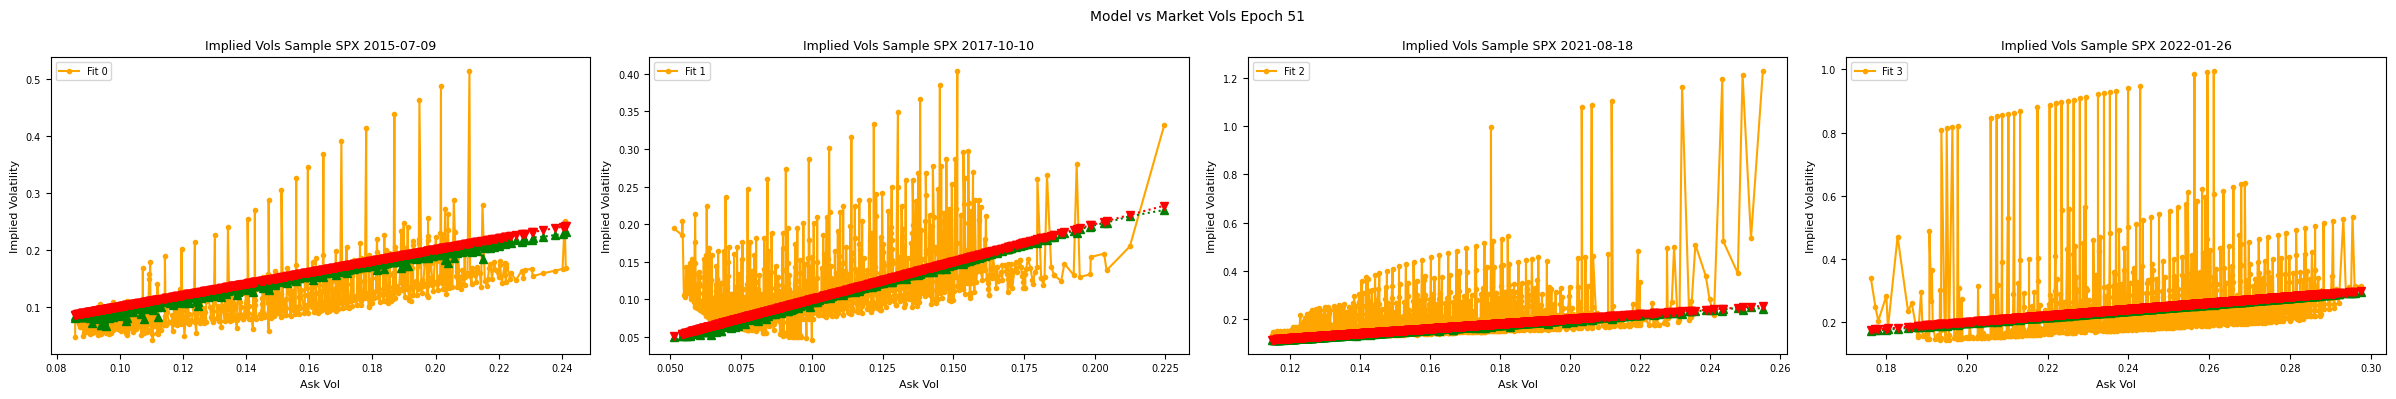

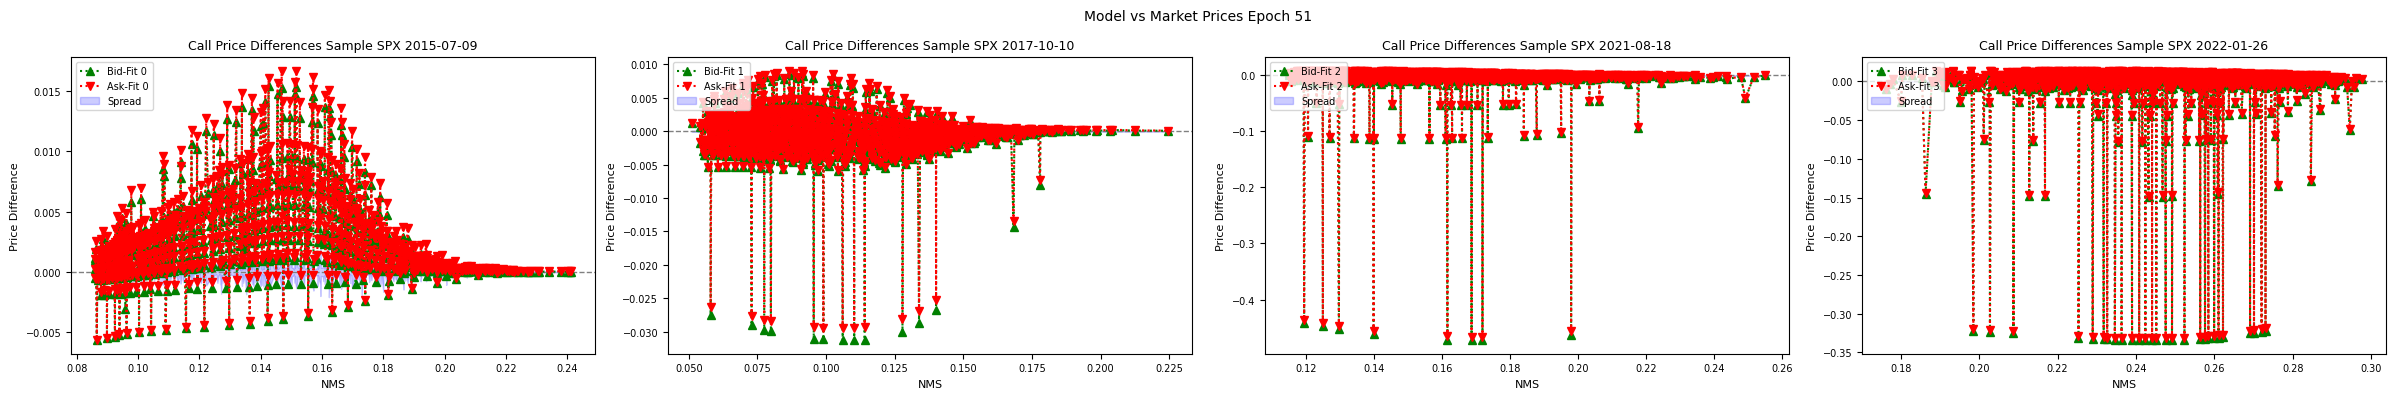

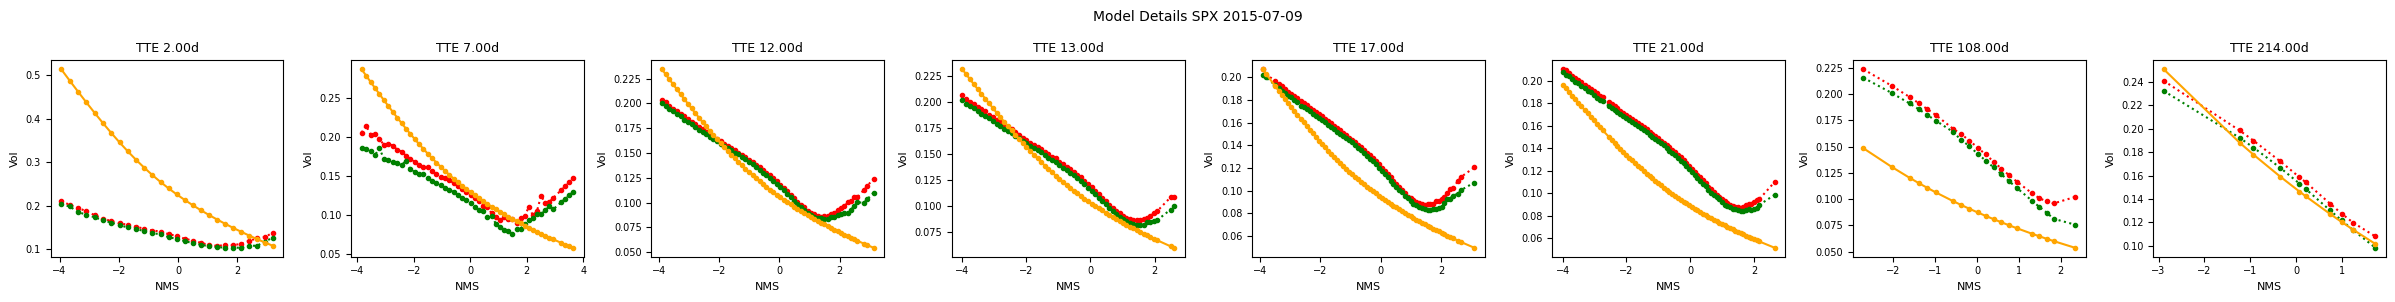

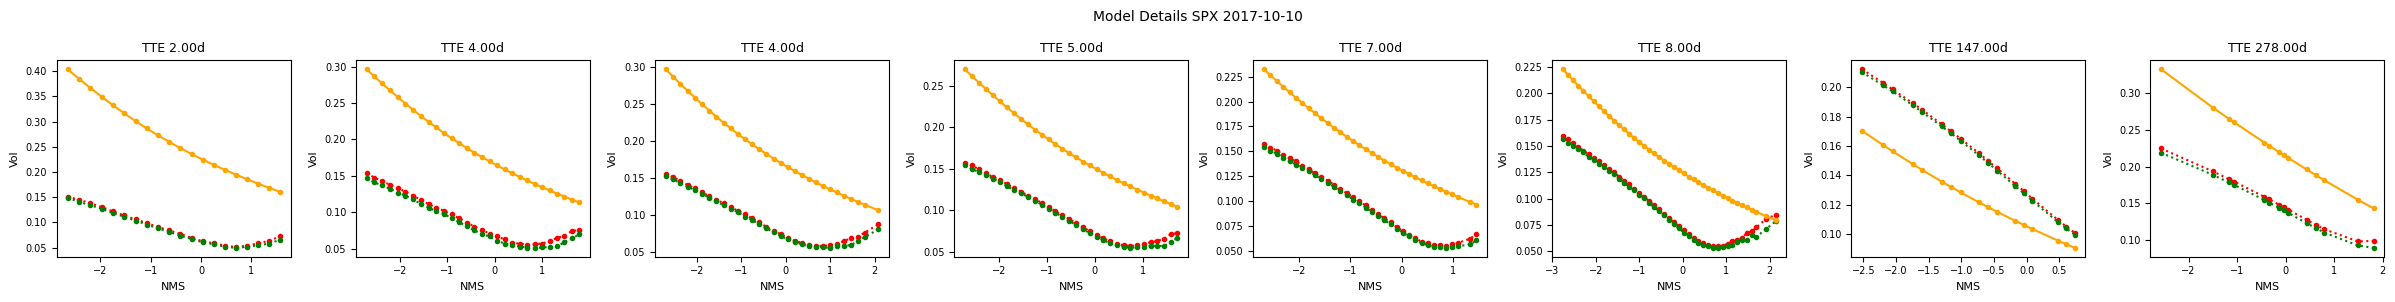

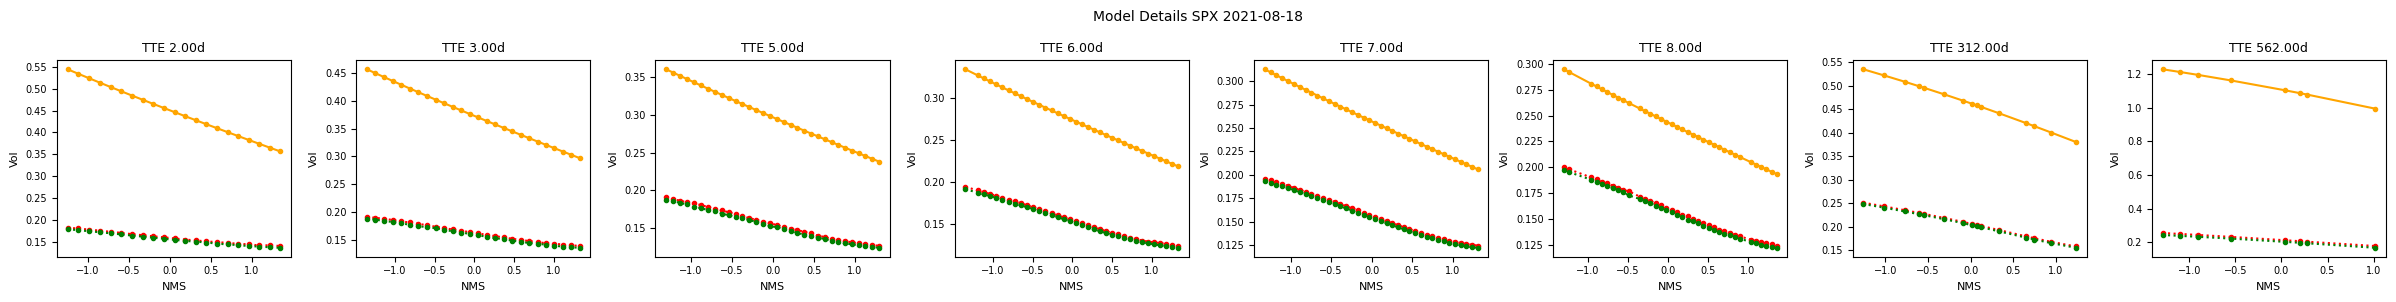

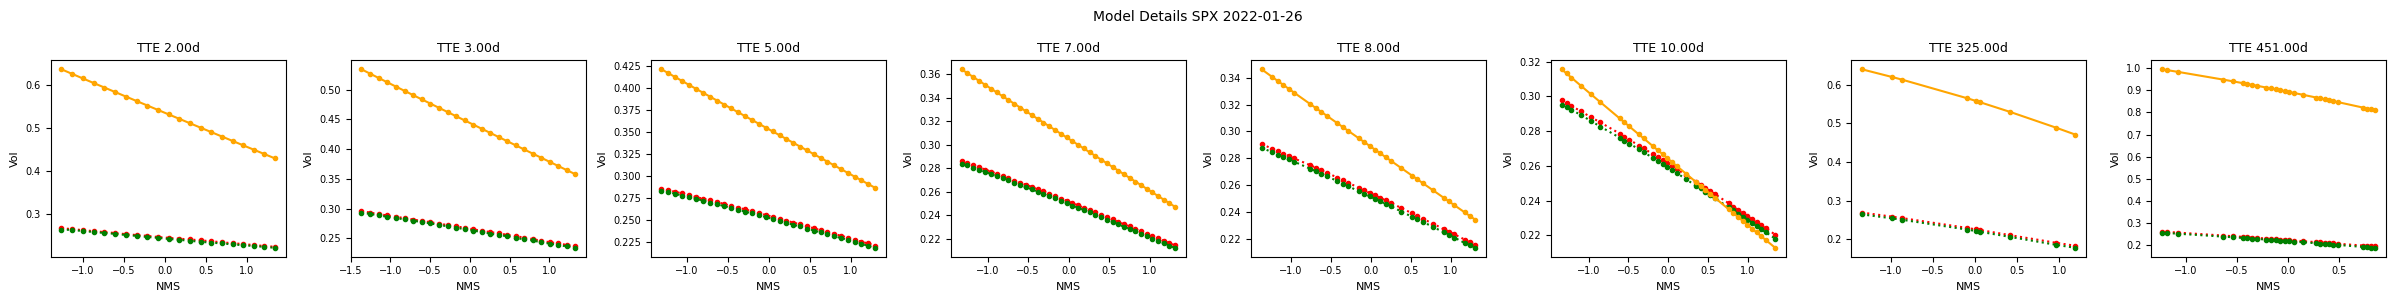

00: Training 'train_sqrtVar_vol_simple' epoch 50/1000 error avg trn 52.18; val 51.36/93.81 [5s 0.97s 0.24s]. LR: 8.41e-04, GN 10.91, excess_weighted: 4.55e-14/1.696e-13, excess_weighted_avg: 0.003689/0.004724, excess_spread: 27.11/47.25, excess_spread_avg: 25.83/47.25, excess: 0.007795/0.008613, excess_avg: 0.007486/0.008613. ETA: 4:05:39.
01:   Epoch 50: Saving new best validation loss 93.81 vs. 97.51 at epoch 49 to '/media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_vol_simple 75c1566e/best.pt'... done; this took 0.042s.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_vol_simple 75c1566e/last.pt... done; this took 0.036s.
00: Training 'train_sqrtVar_vol_simple' epoch 51/1000 error avg trn 51.17; val 51.09/96.18 [4s 0.97s 0.24s]. LR: 8.36e-04, GN 2.005, excess_weighted: 4.57e-14/1.742e-13, excess_weighted_avg: 0.003691/0.004838, excess_spread: 27.24/48.52, excess_spread_avg: 25.95/48.52

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "sqrtVar",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    # rarely touch these
    weight_by_spread = True,

    encoder = DeepSetEncoderFactory(
        num_compress = 128,
        inside_tanh = True,
        set_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32,
            activation = 'Softplus',
        ),
        fix_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64,
            activation = 'Softplus',
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 2,
            num_width = 64,
            activation = 'Softplus',    
        )
    ),
)

run( ipynbname.name(), version="1.1", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch =  10 )
